# Exercise Sheet 5 (programming part, unsolved)
*Machine Learning for Data Science, Winter Semester 2026/27 — Prof. Dr.-Ing. Gerhard Wunder, Freie Universität Berlin*

1. Maxim Zotov
1. Furkan Dursun
1. Lewin Ahlgrimm

We first import the relevant libraries.

In [1]:
import numpy
import scipy
import scipy.spatial
import scipy.sparse
import scipy.sparse.csgraph
import sklearn
import sklearn.datasets
import sklearn.decomposition
import torchvision
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt
lcm = matplotlib.colors.ListedColormap

## Exercise 3 (10 + 10 P)

In this exercise we perform a clustering of the Iris dataset, which was also used in the previous two assignments.

The dataset associates to each plant instance four measurements. The dataset also includes for each instance the type of iris plant (iris setosa, iris versicolour, iris virginica) which we treat here as metadata. Overall, the Iris dataset has 150 instances, and can be stored as an array of size 150 x 4. The following cell loads the dataset and performs some normalization. We also generate a PCA representation of the data for plotting purposes.

In [2]:
dataset = sklearn.datasets.load_iris()

X = numpy.log(0.1+dataset['data'])
T = dataset['target']
pca = sklearn.decomposition.PCA(n_components=2)
Z = pca.fit_transform(X)

We focus on one of the simplest clustering methods, which is to find the connected components of a graph associated to the dataset. We consider a graph where two nodes are connected if the distance between the corresponding instances (after dataset normalization) is below some threshold value `delta`.

**(a)** Implement this simple clustering method. *(Hint: you can make use of the method `scipy.sparse.csgraph.connected_components` to find the connected components associated to a particular adjacency matrix.)*

In [3]:
pca.explained_variance_ratio_

array([0.96783774, 0.01698453])

In [4]:
Z

array([[-1.45630601e+00,  5.80355242e-02],
       [-1.45130534e+00, -9.34509615e-02],
       [-1.49866330e+00, -4.37405480e-02],
       [-1.42423844e+00, -9.50572760e-02],
       [-1.46027904e+00,  7.57903440e-02],
       [-9.36732500e-01,  2.04026054e-01],
       [-1.23096292e+00,  2.20828361e-02],
       [-1.42055136e+00,  1.75974575e-02],
       [-1.46132610e+00, -1.63047610e-01],
       [-1.74857927e+00, -1.11000089e-01],
       [-1.41710441e+00,  1.21189029e-01],
       [-1.39114816e+00, -4.37213767e-03],
       [-1.78507660e+00, -1.40252087e-01],
       [-1.92258682e+00, -1.55213060e-01],
       [-1.53031810e+00,  2.40801475e-01],
       [-1.00417421e+00,  3.45163368e-01],
       [-1.07767527e+00,  2.32749988e-01],
       [-1.22113845e+00,  8.58523828e-02],
       [-1.11143087e+00,  1.79264788e-01],
       [-1.19003278e+00,  1.51671910e-01],
       [-1.34582049e+00,  3.25234960e-02],
       [-1.00597117e+00,  1.49494769e-01],
       [-1.64360534e+00,  8.05315434e-02],
       [-7.

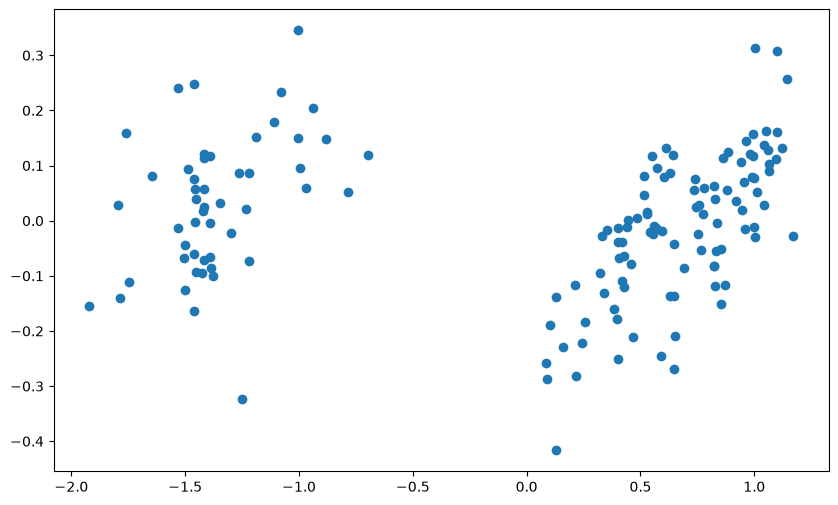

In [5]:
plt.figure(figsize=(10,6))
plt.scatter(Z[:, 0], Z[:, 1])
plt.show()

In [6]:
class ConnectedComponentsClustering:

    def __init__(self,delta):
        self.delta = delta

    def fit_predict(self, X):
        dists = scipy.spatial.distance.cdist(X, X) # pairwise
        adjacency_matrix = dists <= self.delta
        return scipy.sparse.csgraph.connected_components(adjacency_matrix, directed=False) # already returns clusters
        # does not give D or A matrix
        # ------------------------------------
        # TODO: Replace by your code
        # ------------------------------------
        # Return (n_components, Y): number of clusters and a cluster label per instance
        # ------------------------------------

The algorithm is now applied to the Iris dataset with a particular threshold value `delta = 0.5`. Results are visualized in a PCA plot, where instances are color-coded according to their cluster.

2


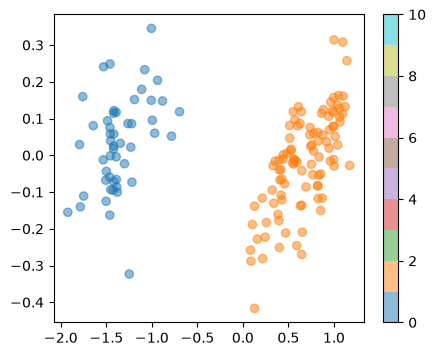

In [7]:
delta = 0.5

n_components, Y = ConnectedComponentsClustering(delta).fit_predict(X)

print(n_components)

plt.figure(figsize=(5,4))
plt.scatter(*Z.T,c=Y,cmap='tab10',vmin=0,vmax=10,alpha=0.5)
plt.colorbar()
plt.show()

Expected output: `2` clusters.

We observe two clusters. Clusters are consistent with what a human can see in the PCA plot.

**(b)** We now would like to compare the taxonomy derived from the clustering above with the actual iris types available as meta-data. Write code that produces a correspondence table linking the clustering to the classification into iris types.

In [8]:
Y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [9]:
Y[numpy.where(T==0)] == 0

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [10]:
T

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [11]:
T = dataset['target']
names = dataset['target_names']

print(f"{"":>10} {"cluster_0":>10} {"cluster_1":>10}")
for id, name in enumerate(names):
    print(f"{name:<10} {numpy.sum(Y[numpy.where(T==id)] == 0):>10} {numpy.sum(Y[numpy.where(T==id)] == 1):>10}")

# ------------------------------------
# ------------------------------------
# Print a table: one row per iris type, one column per cluster, entries = number of instances
# ------------------------------------

            cluster_0  cluster_1
setosa             50          0
versicolor          0         50
virginica           0         50


Expected output:
```
           cluster_0 cluster_1
setosa            50          0
versicolor         0         50
virginica          0         50
```

We observe a one-to-one correspondence between cluster 0 and the type iris setosa. The two other iris types (versicolor and virginica) are grouped in the second cluster.

## Exercise 4 (10 + 10 + 10 P)

In this exercise, we consider clustering of fashion items from the FashionMNIST dataset. The FashionMNIST dataset consists of 60000 fashion items, each of which coming as a 28 x 28 grayscale image. For the purpose of limiting computations, we consider a subset of 1000 instances from this dataset, and thus, extract a dataset of size 1000 x 784 (the 784 dimensions correspond to representing images as a flat vector). We also generate a PCA representation of the data for visualization purposes.

In [12]:
X = torchvision.datasets.FashionMNIST('.',download=True).data.numpy()

numpy.random.seed(0)
R = numpy.random.permutation(len(X))[:1000]
X = X[R].reshape(-1,784)

X = X / 255.0

Z = sklearn.decomposition.PCA(n_components=2).fit_transform(X)

The first 50 images of our dataset are visualized below:

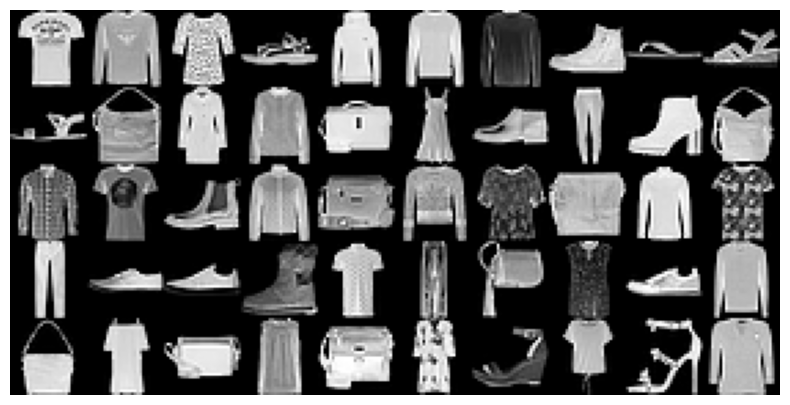

In [13]:
plt.figure(figsize=(10,5))
plt.axis('off')
plt.imshow(X[:50].reshape(5,10,28,28).transpose(0,2,1,3).reshape(5*28,10*28),cmap='gray',vmin=0,vmax=1)
plt.show()

**(a)** Implement a rudimentary version of K-Means, where the cluster centers are initialized to the first few examples of the dataset, and where the number of iterations is fixed to 100.

In [14]:
class KMeans:

    def __init__(self,n_clusters):
        self.n_clusters = n_clusters

    def fit(self,X):

        # ------------------------------------
        self.cluster_centers_ = X[:self.n_clusters].astype(float).copy()
        print(self.cluster_centers_.shape)
        for _ in range(100):
            # step one of algo (fix mu)
            c_i = self.predict(X)

            # step 2 of algo (fix c_i)
            new_centers = self.cluster_centers_.copy()
            for k in range(self.n_clusters):
                cluster = X[c_i==k]
                if len(cluster) > 0:
                    new_centers[k] = numpy.mean(cluster, axis=0)
            self.cluster_centers_ = new_centers.copy()
        # ------------------------------------
        # Initialize self.cluster_centers_ (K x 784) to the first K examples, then alternate assignment / centroid update 100 times
        # ------------------------------------

    def predict(self,X):

        D = scipy.spatial.distance.cdist(X,self.cluster_centers_)
        # D-distance between each point and cluster, shape (1000, 20)
        return numpy.argmin(D,axis=1) # cluster number to which point has minimal distance
print("Shape:", X.shape, "Dtype:", X.dtype)
print("Unique rows in first 20:", len(numpy.unique(X[:20], axis=0)))
model = KMeans(20)
model.fit(X)

Shape: (1000, 784) Dtype: float64
Unique rows in first 20: 20
(20, 784)


The outcome of your clustering procedure can be visualized in the following PCA plot color-coded by cluster membership.

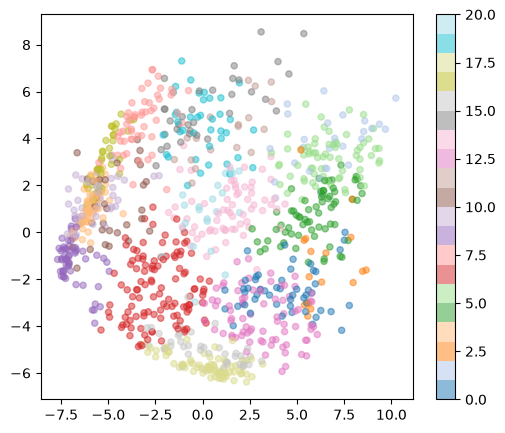

In [15]:
numpy.random.seed(0)
Y = model.predict(X)

plt.figure(figsize=(6,5))
plt.scatter(*Z.T,c=Y,s=20,vmin=0,vmax=20,cmap='tab20',alpha=0.5)
plt.colorbar()
plt.show()

**(b)** We now would like to get insights into what are prototypical fashion items in our dataset. For this, we consider the cluster centers learned by k-means. Extract these cluster centers and visualize them as images.

In [16]:
model.cluster_centers_[0].reshape(28, 28).shape

(28, 28)

[]

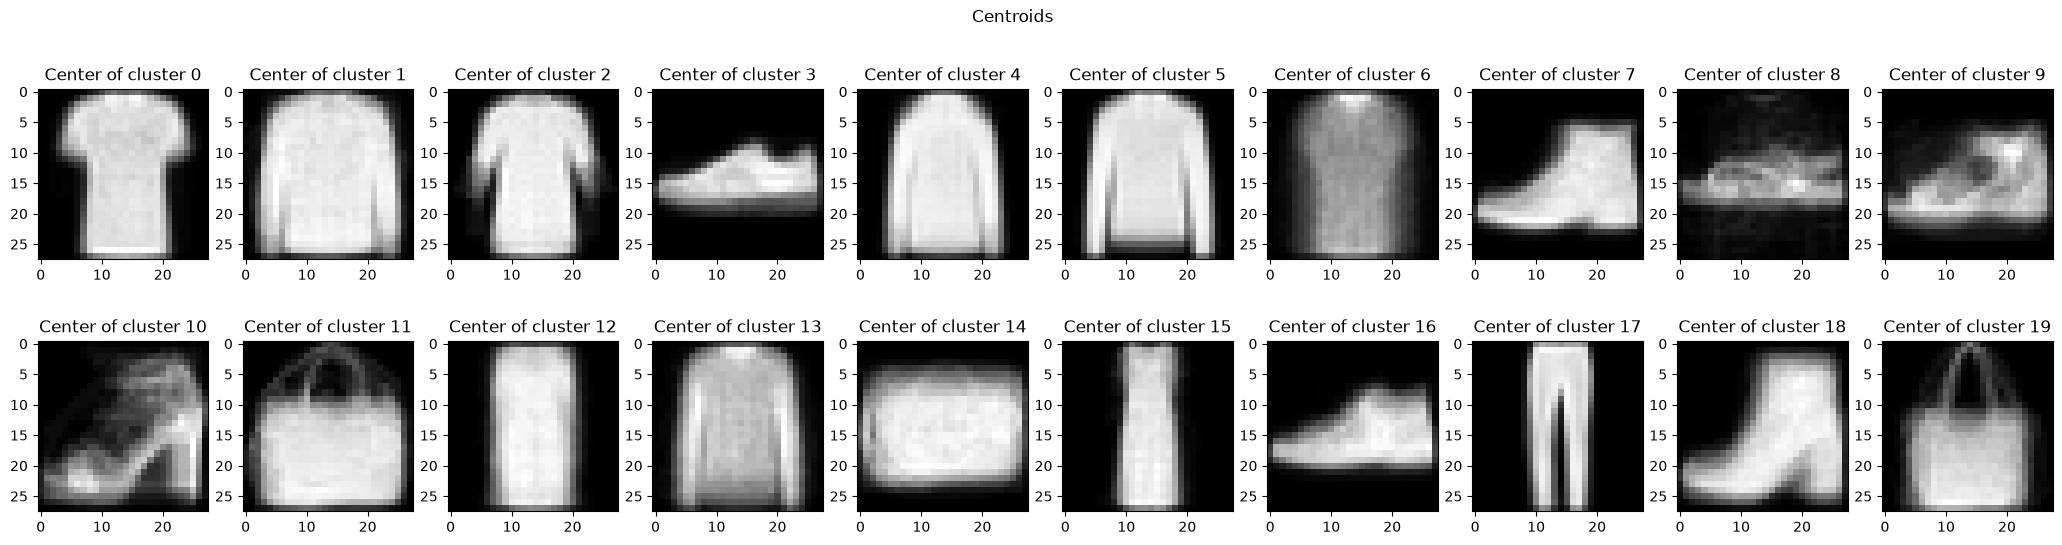

In [17]:
# ------------------------------------
# TODO: Replace by your code
# ------------------------------------
# Show the 20 cluster centers (model.cluster_centers_) as 28x28 images, e.g. as a 2x10 mosaic
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(26, 6))
axs = axs.flatten()
plt.suptitle("Centroids")
for i, im in enumerate(model.cluster_centers_):
    axs[i].imshow(im.reshape(28, 28), cmap='gray')
    axs[i].set_title(f"Center of cluster {i}")
plt.plot()
# ------------------------------------

**(c)** Lastly, we would like to know how well these cluster centers describe our data. Using the formulas presented in the lecture, compute the total variance, the within-cluster variance, the between-cluster variance, and the percentage of explained variance.

In [18]:
# ------------------------------------
# TODO: Replace by your code
# ------------------------------------
# Print total, between-cluster, within-cluster variance and the explained-variance percentage
total_variance = X.var(axis=0).sum()
total_mu = X.mean(axis=0)
between_cluster_variance = 0
within_cluster_variance = 0

for k in range(model.n_clusters):
    X_in_cluster = X[Y==k]
    within_cluster_variance += (numpy.sum((X_in_cluster - model.cluster_centers_[k]) ** 2))/len(X)
    within_cluster_mu = numpy.mean(X_in_cluster, axis=0)
    between_cluster_variance += len(X_in_cluster) * ((within_cluster_mu - total_mu) ** 2).sum()/len(X)

explained_variance = between_cluster_variance / total_variance * 100
print(f"Total variance {total_variance:>.3f}")
print(f"Between-cluster variance {between_cluster_variance:.3f}")
print(f"Within-cluster variance {within_cluster_variance:.3f}")
print(f"Explained variance (%) {explained_variance:.2f}")
# ------------------------------------

Total variance 68.120
Between-cluster variance 41.579
Within-cluster variance 26.541
Explained variance (%) 61.04


Expected output:
```
Total variance             68.120
Between-cluster variance   41.579
Within-cluster variance    26.541

Explained variance (%)     61.04%
```

We observe that a bit more than half of the variance in the data is captured by the clustering, which is quite good, considering that the data is high-dimensional. Note that a higher explained variance could be obtained by incorporating more clusters, however that would come at the cost of making the data description potentially too complex for the end user.